<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta6_g%C3%B6rev6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: Tesla T4


CUDA Kullanılabilir mi?: True


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 116 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


CUDA Hough Line Kernel Çalışma Süresi: 2.44 ms


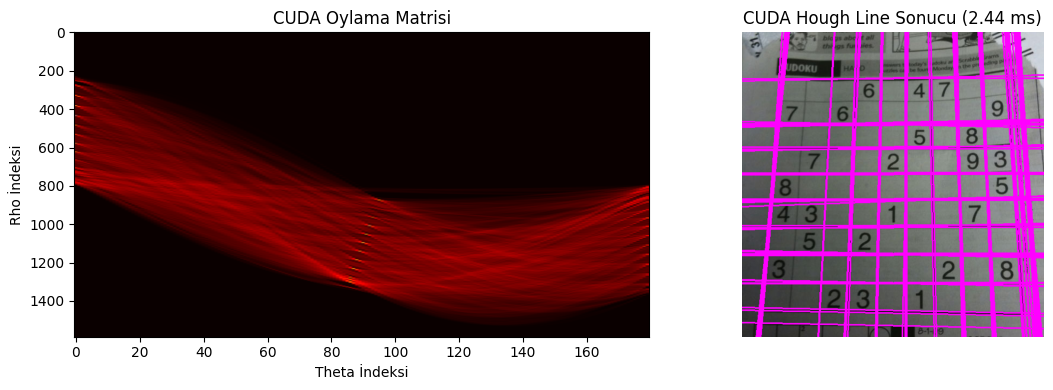

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request
from numba import cuda
import math
import time

print("CUDA Kullanılabilir mi?:", cuda.is_available())

url = 'https://raw.githubusercontent.com/opencv/opencv/master/samples/data/sudoku.png'
req = urllib.request.urlopen(url)
arr = np.asarray(bytearray(req.read()), dtype=np.uint8)
img = cv2.imdecode(arr, cv2.IMREAD_COLOR)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(gray, 50, 150)

edge_y, edge_x = np.nonzero(edges)
edge_x = edge_x.astype(np.int32)
edge_y = edge_y.astype(np.int32)
num_edges = len(edge_x)

thetas = np.deg2rad(np.arange(-90.0, 90.0, 1.0)).astype(np.float32)
cos_vals = np.cos(thetas).astype(np.float32)
sin_vals = np.sin(thetas).astype(np.float32)
num_thetas = len(thetas)

height, width = edges.shape
diag_len = int(math.ceil(math.sqrt(height**2 + width**2)))
rhos = np.arange(-diag_len, diag_len + 1, 1.0).astype(np.float32)
num_rhos = len(rhos)

@cuda.jit
def hough_line_cuda_kernel(edge_x, edge_y, num_edges, cos_vals, sin_vals, num_thetas, rho_min, rho_step, num_rhos, acc):
    idx = cuda.grid(1)
    if idx < num_edges:
        x = edge_x[idx]
        y = edge_y[idx]
        for t_idx in range(num_thetas):
            rho = x * cos_vals[t_idx] + y * sin_vals[t_idx]
            r_idx = int(round((rho - rho_min) / rho_step))
            if 0 <= r_idx < num_rhos:
                cuda.atomic.add(acc, (r_idx, t_idx), 1)

d_edge_x = cuda.to_device(edge_x)
d_edge_y = cuda.to_device(edge_y)
d_cos = cuda.to_device(cos_vals)
d_sin = cuda.to_device(sin_vals)
d_acc = cuda.device_array((num_rhos, num_thetas), dtype=np.int32)
d_acc[:] = 0

threads_per_block = 256
blocks_per_grid = (num_edges + threads_per_block - 1) // threads_per_block

hough_line_cuda_kernel[blocks_per_grid, threads_per_block](
    d_edge_x, d_edge_y, num_edges, d_cos, d_sin, num_thetas, float(rhos[0]), 1.0, num_rhos, d_acc
)
cuda.synchronize()

d_acc[:] = 0
start_gpu = time.time()
hough_line_cuda_kernel[blocks_per_grid, threads_per_block](
    d_edge_x, d_edge_y, num_edges, d_cos, d_sin, num_thetas, float(rhos[0]), 1.0, num_rhos, d_acc
)
cuda.synchronize()
gpu_time_ms = (time.time() - start_gpu) * 1000

accumulator = d_acc.copy_to_host()
print(f"CUDA Hough Line Kernel Çalışma Süresi: {gpu_time_ms:.2f} ms")

threshold = int(0.45 * accumulator.max())
rho_idxs, theta_idxs = np.where(accumulator >= threshold)

img_cuda_lines = img.copy()
for r_idx, t_idx in zip(rho_idxs, theta_idxs):
    rho = rhos[r_idx]
    theta = thetas[t_idx]
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a * rho
    y0 = b * rho
    x1 = int(x0 + 1000 * (-b))
    y1 = int(y0 + 1000 * (a))
    x2 = int(x0 - 1000 * (-b))
    y2 = int(y0 - 1000 * (a))
    cv2.line(img_cuda_lines, (x1, y1), (x2, y2), (255, 0, 255), 2)  # Mor/Pembe

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(accumulator, cmap='hot', aspect='auto')
plt.title('CUDA Oylama Matrisi')
plt.xlabel('Theta İndeksi')
plt.ylabel('Rho İndeksi')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img_cuda_lines, cv2.COLOR_BGR2RGB))
plt.title(f'CUDA Hough Line Sonucu ({gpu_time_ms:.2f} ms)')
plt.axis('off')

plt.tight_layout()
plt.show()